In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('retail_sales_dataset.csv')

In [ ]:
df.isnull().sum()

In [ ]:
df.dropna(inplace=True)

In [ ]:
df.sort_values(by='order_id', inplace=True)

In [ ]:
df.reset_index(drop=True, inplace=True)

In [ ]:
df['return_flag'] = df['return_flag'].astype(bool)

In [14]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
pd.set_option('display.max_columns', None)

In [ ]:
df[df['quantity']<=0]

In [ ]:
df['age'].max()

In [ ]:
df['order_date'].dtypes

In [ ]:
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed', errors='coerce')

In [ ]:
ind=df[df['days_to_ship']==-1]
df=df.drop(ind.index)

In [ ]:
df[df['product_name']=='Comic Book']

In [ ]:
for col in df.columns:
    print(f'{col}:')
    print(df[col].describe())
    print(df[col].sort_values().unique())
    print()

In [ ]:
df.to_csv('retail_cleaned.csv', index=False)

In [ ]:
df = pd.read_csv('retail_cleaned.csv')

In [ ]:
df.groupby('product_name')['unit_price'].agg(['count', 'nunique', 'min', 'max'])

In [ ]:
df[df['product_name']=='Cricket Bat'][['order_date', 'unit_price']].sort_values('order_date')

In [ ]:
df.groupby('product_name')['unit_price'].describe()

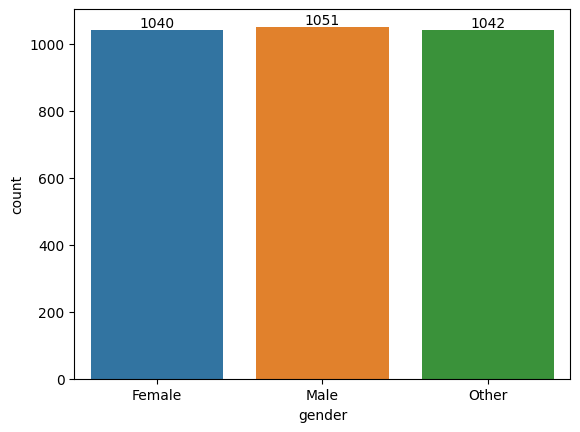

In [15]:
ax = sns.countplot(x='gender', data=df, hue='gender', legend=False)
for bars in ax.containers:
    ax.bar_label(bars)

In [ ]:
sns.set_palette('tab10')

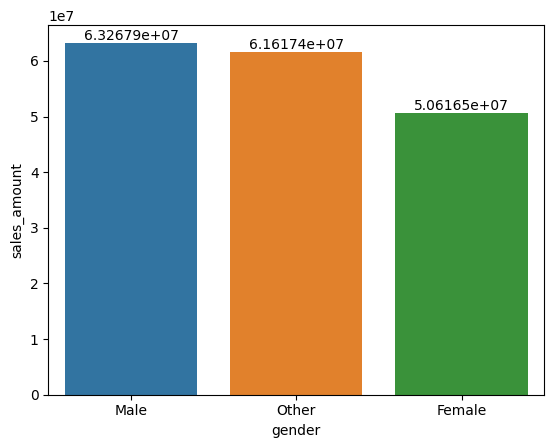

In [16]:
sales_gen = df.groupby('gender', as_index=False)['sales_amount'].sum().sort_values('sales_amount', ascending=False)
ax = sns.barplot(x='gender', y='sales_amount', data=sales_gen, hue='gender')
for bars in ax.containers:
    ax.bar_label(bars)

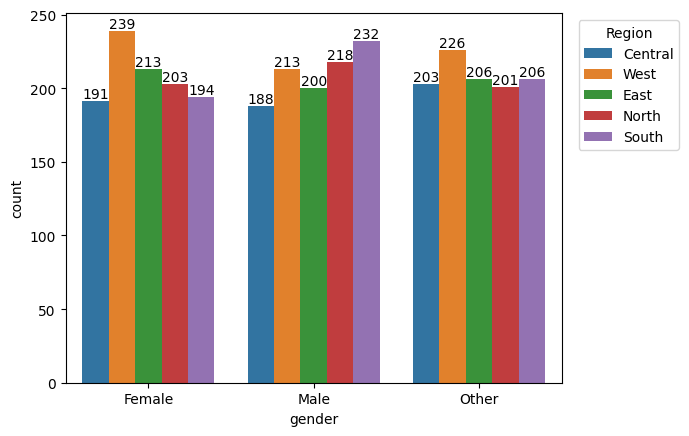

In [17]:
ax = sns.countplot(x='gender', hue='region', data=df)
ax.legend(title='Region', bbox_to_anchor=(1.02,1), loc='upper left')

for container in ax.containers:
    ax.bar_label(container)

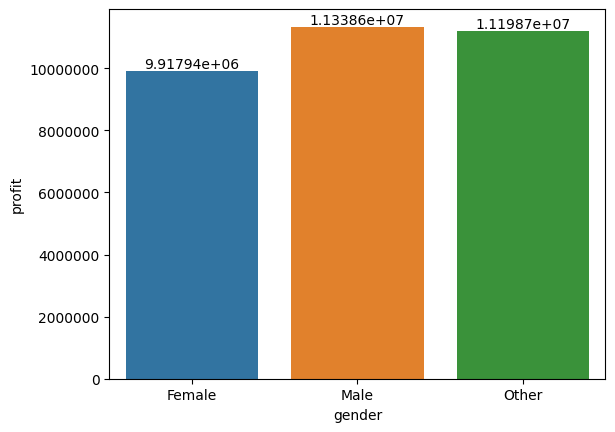

In [18]:
highest_profit = df.groupby('gender', as_index=False)['profit'].sum()
ax = sns.barplot(x='gender', y='profit', hue='gender', data=highest_profit)
for cont in ax.containers:
    ax.bar_label(cont)
ax.ticklabel_format(style='plain', axis='y')

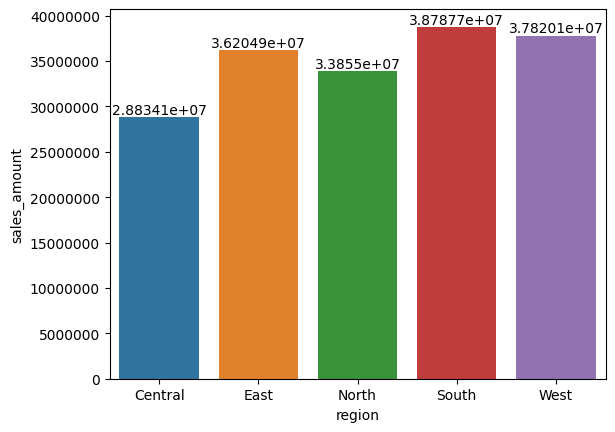

In [19]:
region_SA = df.groupby('region', as_index=False)['sales_amount'].sum()
ax = sns.barplot(x='region', y='sales_amount', hue='region', data=region_SA)
for cont in ax.containers:
    ax.bar_label(cont)
ax.ticklabel_format(style='plain', axis='y')

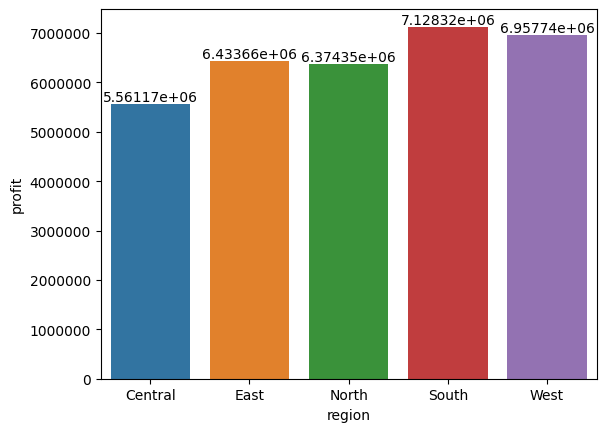

In [20]:
region_profit = df.groupby('region', as_index=False)['profit'].sum()
ax = sns.barplot(x='region', y='profit', hue='region', data=region_profit)
for cont in ax.containers:
    ax.bar_label(cont)
ax.ticklabel_format(style='plain', axis='y')

<Axes: xlabel='age', ylabel='sales_amount'>

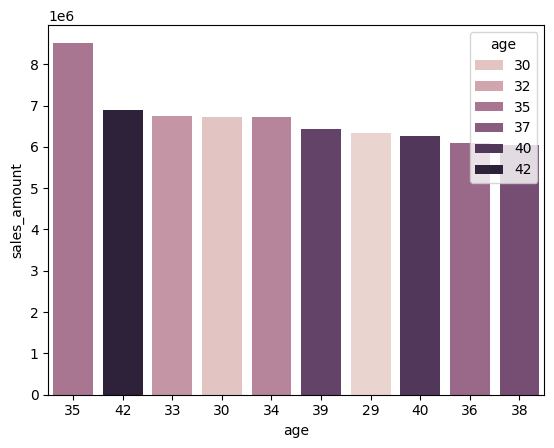

In [21]:
most_age_people = df.groupby('age', as_index=False)['sales_amount'].sum().sort_values('sales_amount', ascending=False).head(10)
sns.barplot(x='age', y='sales_amount', data=most_age_people, hue='age', order=most_age_people['age'])

<Axes: xlabel='age', ylabel='profit'>

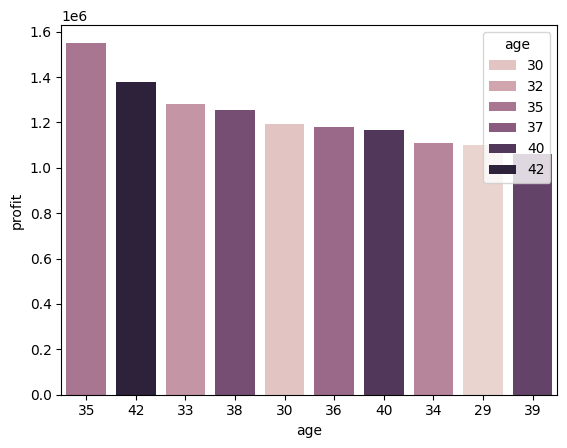

In [22]:
most_age_people = df.groupby('age', as_index=False)['profit'].sum().sort_values('profit', ascending=False).head(10)
sns.barplot(x='age', y='profit', data=most_age_people, hue='age', order=most_age_people['age'])

<Axes: xlabel='gender', ylabel='count'>

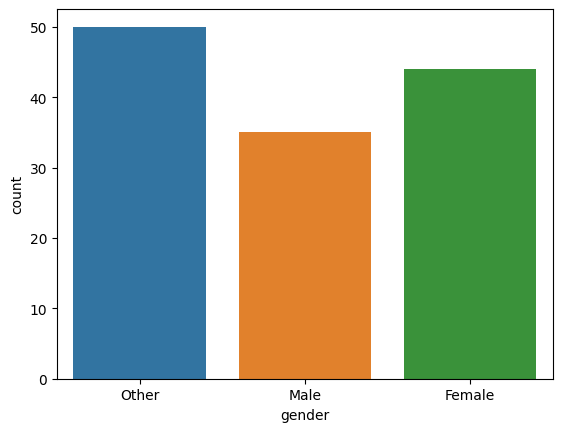

In [23]:
age_gender = df[df['age']==35]
sns.countplot(x='gender', data=age_gender, hue='gender')

<Axes: xlabel='city', ylabel='profit'>

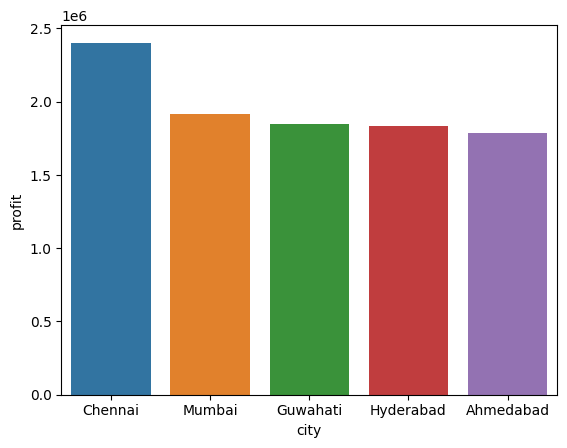

In [24]:
city_profit = df.groupby('city', as_index=False)['profit'].sum().sort_values('profit', ascending=False).head()
sns.barplot(x='city', y='profit', data=city_profit, hue='city')

<Axes: xlabel='product_category', ylabel='profit'>

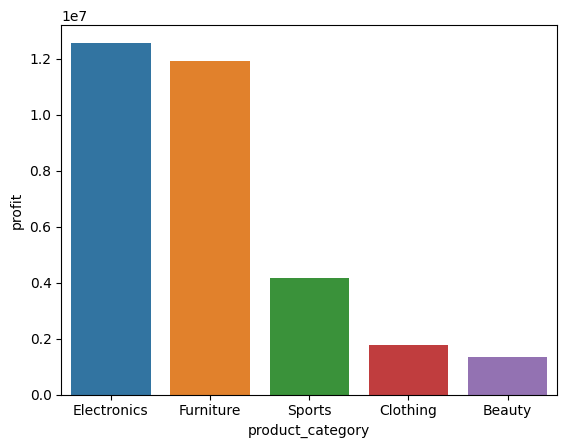

In [25]:
pc_profit = df.groupby('product_category', as_index=False)['profit'].sum().sort_values('profit', ascending=False).head()
sns.barplot(x='product_category', y='profit', data=pc_profit, hue='product_category')

<Axes: xlabel='product_name', ylabel='profit'>

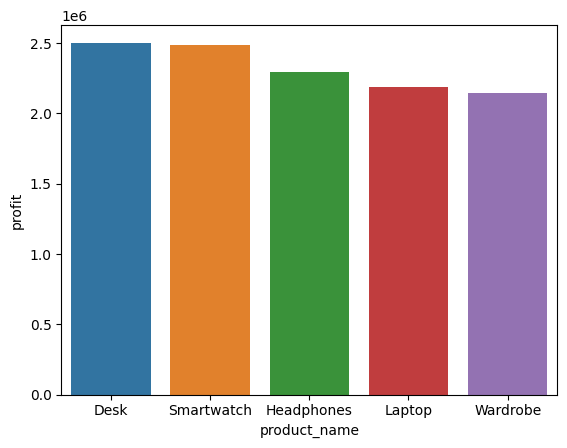

In [26]:
pn_profit = df.groupby('product_name', as_index=False)['profit'].sum().sort_values('profit', ascending=False).head()
sns.barplot(x='product_name', y='profit', data=pn_profit, hue='product_name')

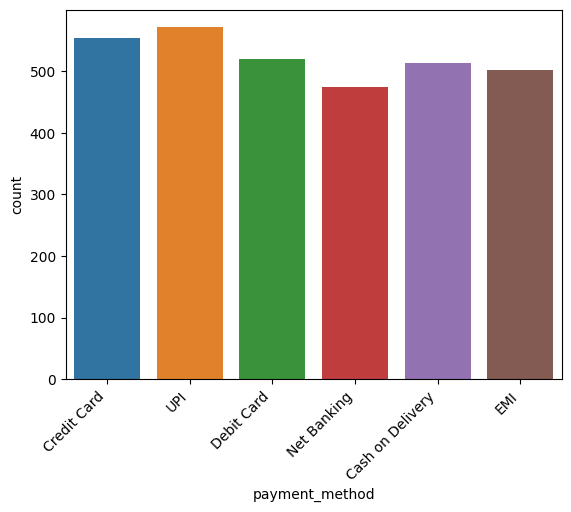

In [27]:
ax= sns.countplot(x='payment_method', data=df, hue='payment_method')
plt.xticks(rotation=45, ha='right')
plt.show()

<Axes: xlabel='product_category', ylabel='rating_count'>

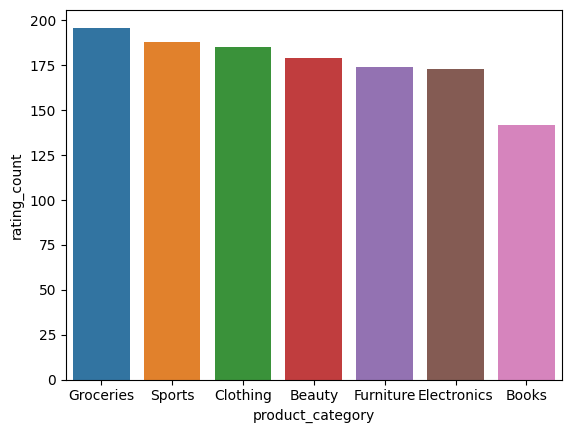

In [28]:
dt = df[df['customer_satisfaction']<3]
low_rating = dt.groupby('product_category').size().reset_index(name='rating_count').sort_values('rating_count', ascending=False)
sns.barplot(x='product_category', y='rating_count', data=low_rating, hue='product_category')

<Axes: xlabel='product_category', ylabel='Returned'>

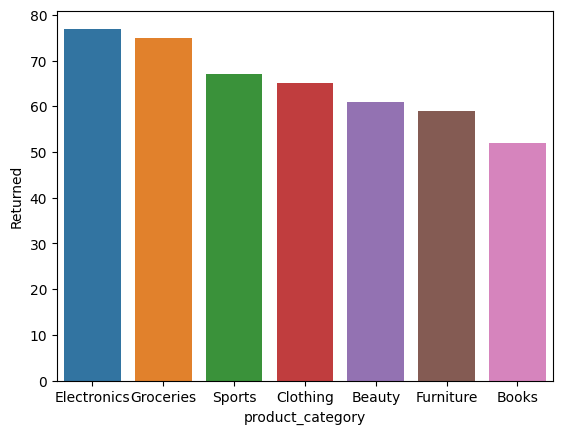

In [29]:
dt = df[df['return_flag']==True]
returned_category = dt.groupby('product_category').size().reset_index(name='Returned').sort_values('Returned',ascending=False)
sns.barplot(x='product_category', y='Returned', data=returned_category, hue='product_category')

<Axes: xlabel='days_to_ship', ylabel='count'>

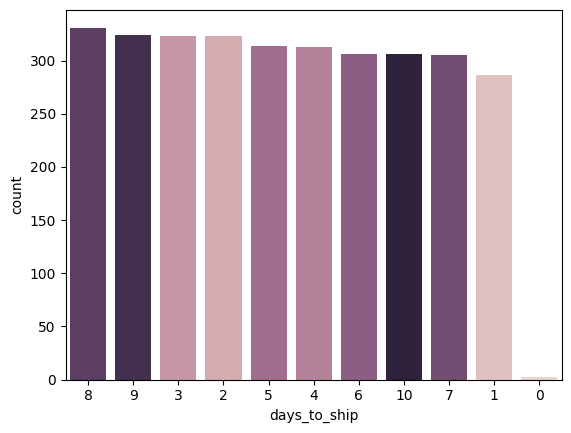

In [30]:
order = df['days_to_ship'].value_counts().index
sns.countplot(x='days_to_ship', data=df, hue='days_to_ship', legend=False, order=order)